### Czyszczenie danych

In [2]:
import pandas as pd
# ustawienie bez notacji wykladniczej
pd.set_option("display.float_format", "{:.2f}".format)

In [ ]:
import glob
import json
import os
import numpy as np
import matplotlib.pyplot as plt

files = sorted(glob.glob("ztm_data/data/*.jsonl"))
print("liczba plikow:", len(files))
print("pierwszy:", files[0], "| ostatni:", files[-1])

# podglad jednego zrzutu z API
with open(files[-2], "r", encoding="utf-8") as f:
    sample_line = json.loads(f.readline())

print("klucze glowne:", list(sample_line.keys()))
print("liczba pojazdow w 1 zrzucie:", len(sample_line["vehicles"]))
print("przykladowy pojazd:", sample_line["vehicles"][0])

In [ ]:
# 14 pelnych dni (bez pierwszego i ostatniego pliku)
selected_files = files[-15:-1]
print("wczytuje dni od:", os.path.basename(selected_files[0]), "do:", os.path.basename(selected_files[-1]))

rows = []
for filepath in selected_files:
    with open(filepath, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            # co 3 linia (~1 min zamiast 20s)
            if i % 3 != 0 or not line.strip():
                continue
            data = json.loads(line)
            for v in data.get("vehicles", []):
                rows.append({
                    "generated": v.get("generated"),
                    "scheduledTripStartTime": v.get("scheduledTripStartTime"),
                    "routeShortName": v.get("routeShortName"),
                    "headsign": v.get("headsign"),
                    "vehicleId": v.get("vehicleId"),
                    "tripId": v.get("tripId"),
                    "speed": v.get("speed"),
                    "lat": v.get("lat"),
                    "lon": v.get("lon"),
                    "gpsQuality": v.get("gpsQuality"),
                    "delay": v.get("delay"),
                })

df = pd.DataFrame(rows)
del rows

print("shape:", df.shape)
print("\nbraki:\n", df.isna().sum())
print("\nduplikaty (vehicleId + generated):", df.duplicated(subset=["vehicleId", "generated"]).sum())
df.describe()

wczytuje dni od: 2026-11-09.jsonl do: 2026-11-22.jsonl
shape: (3862065, 11)

braki:
 generated                     0
scheduledTripStartTime    67457
routeShortName                0
headsign                      0
vehicleId                     0
tripId                    67645
speed                         0
lat                           0
lon                           0
gpsQuality                    0
delay                         0
dtype: int64

duplikaty (vehicleId + generated): 15815


,vehicleId,tripId,speed,lat,lon,gpsQuality,delay
count,3862065.00,3794420.00,3862065.00,3862065.00,3862065.00,3862065.00,3862065.00
mean,107978.56,100.09,14.14,54.33,18.60,2.99,123.09
std,63771.18,100.16,16.11,1.34,0.46,0.12,373.36
min,1.00,11.00,0.00,0.00,0.00,0.00,-1079.00
25%,501.00,21.00,0.00,54.34,18.58,3.00,-1.00
50%,145754.00,71.00,10.00,54.36,18.60,3.00,17.00
75%,146137.00,121.00,25.00,54.39,18.64,3.00,126.00
max,205725.00,512.00,95.00,54.48,18.93,3.00,18203.00


brak tripId - przyklady:
   routeShortName headsign  speed  delay
3             149               0      0
9               2               0      0
12            175               0      0
14            117               0      0
19            143              60      0

gpsQuality value_counts:
 gpsQuality
3    3849227
2       7153
0       5685
Name: count, dtype: int64
lat < 54.0 (poza Pomorzem): 2352


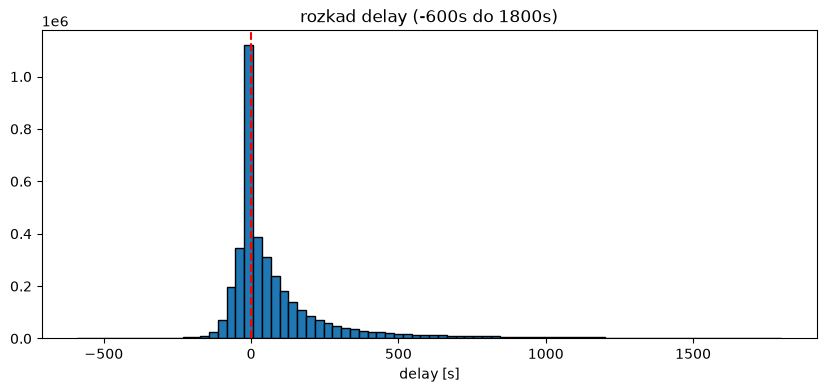

In [ ]:
# podglad wierszy bez tripId (zjazdy/przejazdy techniczne pewnie)
print("brak tripId - przyklady:")
print(df[df["tripId"].isna()][["routeShortName", "headsign", "speed", "delay"]].head(5))

# podglad bledow GPS (lat == 0 lub gpsQuality == 0)
print("\ngpsQuality value_counts:\n", df["gpsQuality"].value_counts())
print("lat < 54.0 (poza Pomorzem):", (df["lat"] < 54.0).sum())

# histogram delay (realistyczny zakres -10 min do +30 min)
plt.figure(figsize=(10, 4))
plt.hist(df[df["delay"].between(-600, 1800)]["delay"], bins=80, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.title("rozkad delay (-600s do 1800s)")
plt.xlabel("delay [s]")
plt.show()

In [ ]:
# czyszczenie brakow, duplikatow i bledow gps
df = df.dropna(subset=["tripId", "scheduledTripStartTime", "delay"])
df = df.drop_duplicates(subset=["vehicleId", "generated"])
df = df[(df["gpsQuality"] >= 2) & (df["lat"] > 54.0) & (df["lon"] > 18.0)]

# usuniecie pojazdow stojacych na petli przed kursem i skrajnych bledow
df = df[~((df["speed"] == 0) & (df["delay"] < -120))]
df = df[df["delay"].between(-600, 3600)]

# nowe cechy z czasu (czas polski)
dt = pd.to_datetime(df["generated"], utc=True).dt.tz_convert("Europe/Warsaw")
df["hour"] = dt.dt.hour
df["day_of_week"] = dt.dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# sortowanie chronologiczne
df = df.sort_values("generated").reset_index(drop=True)

print("po czyszczeniu:", df.shape)
df[["speed", "lat", "lon", "hour", "day_of_week", "delay"]].describe()

/tmp/ipykernel_1245636/1085326449.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = dt.dt.dayofweek


po czyszczeniu: (3754865, 14)


,speed,lat,lon,hour,day_of_week,delay
count,3754865.00,3754865.00,3754865.00,3754865.00,3754865.00,3754865.00
mean,14.30,54.36,18.61,12.91,2.74,120.19
std,16.08,0.04,0.06,5.26,1.92,288.67
min,0.00,54.24,18.35,0.00,0.00,-482.00
25%,0.00,54.34,18.58,8.00,1.00,-1.00
50%,10.00,54.36,18.60,13.00,3.00,21.00
75%,25.00,54.39,18.64,17.00,4.00,130.00
max,95.00,54.48,18.93,23.00,6.00,3600.00


In [ ]:
# macierz korelacji
corr = df[["speed", "lat", "lon", "hour", "day_of_week", "is_weekend", "delay"]].corr()
corr["delay"].sort_values(ascending=False)

delay          1.00
hour           0.06
lon           -0.01
speed         -0.01
day_of_week   -0.07
lat           -0.09
is_weekend    -0.10
Name: delay, dtype: float64

## Dodatki zeby poprawic model

In [ ]:
# wyliczamy czas od planowanego startu kursu w minutach
gen_dt = pd.to_datetime(df["generated"], utc=True)
sched_dt = pd.to_datetime(df["scheduledTripStartTime"], utc=True)
df["minutes_since_start"] = (gen_dt - sched_dt).dt.total_seconds() / 60.0

# odfiltrowujemy bledy (np. ujemny czas lub kursy powyzej 3h)
df = df[df["minutes_since_start"].between(0, 180)].reset_index(drop=True)

# godziny szczytu (7-9 lub 15-17 w dni robocze)
df["is_rush_hour"] = (
    (df["is_weekend"] == 0) &
    (df["hour"].isin([7, 8, 9, 15, 16, 17]))
).astype(int)

### To musi tu byc bo inaczej na laptopie nie odpala mi sie ze wzgledu na brak ramu

In [ ]:
cols_to_drop = ["generated", "scheduledTripStartTime", "vehicleId", "tripId", "gpsQuality"]
df = df.drop(columns=cols_to_drop, errors="ignore")

df["routeShortName"] = df["routeShortName"].astype("category")
df["speed"] = df["speed"].astype("float32")
df["lat"] = df["lat"].astype("float32")
df["lon"] = df["lon"].astype("float32")
df["delay"] = df["delay"].astype("int32")
df["minutes_since_start"] = df["minutes_since_start"].astype("float32")
df["hour"] = df["hour"].astype("int8")
df["day_of_week"] = df["day_of_week"].astype("int8")
df["is_weekend"] = df["is_weekend"].astype("int8")
df["is_rush_hour"] = df["is_rush_hour"].astype("int8")

NameError: name 'df' is not defined

In [ ]:
# zapis czystego zbioru
df.to_pickle("ztm_data/ztm_cleaned.pkl")

: 